# 성능확인 — Tester_branch

병합이 끝난 `코드_공유.py` 의 코드 **전체**를 옮겨 실행하고, 두 모델의 **F1 score 와 Accuracy** 를 비교합니다.

## 1. 코드_공유.py 전체 실행

(40000, 30) (10000, 30)
[DecisionTree] 최적 하이퍼파라미터 : {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 5}
[DecisionTree] CV F1 (best)      : 0.3422
[DecisionTree] Test F1       : 0.3566
[DecisionTree] Test Accuracy : 0.8315


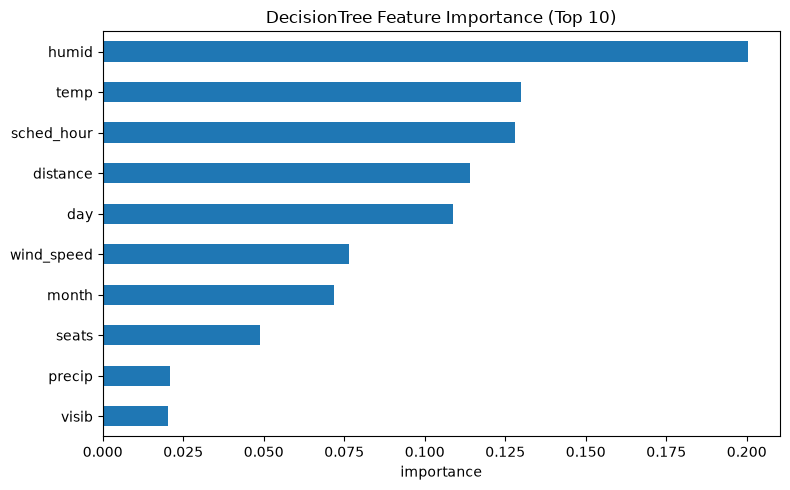

[XGBoost] 최적 하이퍼파라미터 : {'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 300}
[XGBoost] CV F1 (best)      : 0.3823
[XGBoost] Test F1       : 0.4036
[XGBoost] Test Accuracy : 0.859


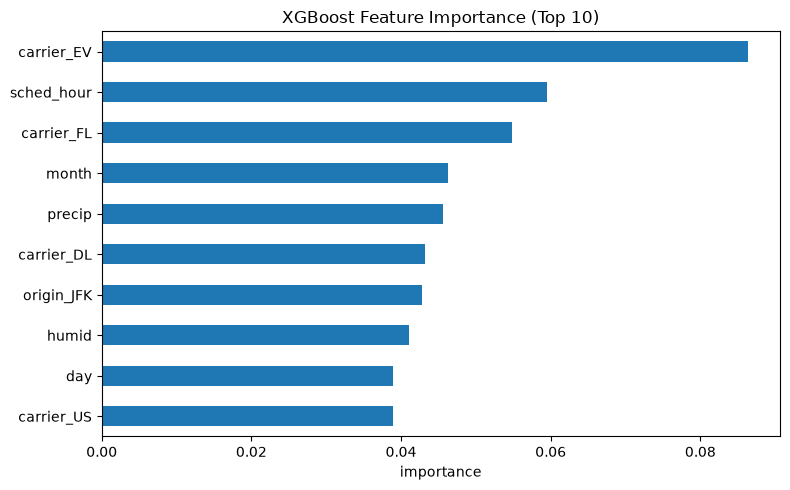

In [1]:
# 코드_공유.py
# 작업자 A, B, Admin 이 함께 사용하는 파일입니다.

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

# 2013년 뉴욕 출발 항공편 표본 50,000건입니다.
# 항공편 정보에 기상 정보와 기체 정보를 미리 결합해 두었습니다.
df = pd.read_csv('flights_ml.csv')

NUM = ['month', 'day', 'sched_hour', 'distance', 'temp', 'humid',
       'wind_speed', 'precip', 'visib', 'seats', 'engines']
CAT = ['carrier', 'origin']

X = pd.get_dummies(df[NUM + CAT], columns=CAT)
X = X.fillna(X.median(numeric_only=True))
y = df['is_delayed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)


####### A 작업자 작업 수행 #######

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, accuracy_score

dt_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15],
    'min_samples_leaf': [1, 5, 20],
}

dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                       param_grid=dt_params, cv=5, scoring='f1', n_jobs=-1)
dt_grid.fit(X_train, y_train)

print('[DecisionTree] 최적 하이퍼파라미터 :', dt_grid.best_params_)
print('[DecisionTree] CV F1 (best)      :', round(dt_grid.best_score_, 4))

dt_best = dt_grid.best_estimator_
dt_pred = dt_best.predict(X_test)
dt_f1 = f1_score(y_test, dt_pred)
dt_acc = accuracy_score(y_test, dt_pred)
print('[DecisionTree] Test F1       :', round(dt_f1, 4))
print('[DecisionTree] Test Accuracy :', round(dt_acc, 4))

# Feature Importance 상위 10개 시각화
dt_imp = pd.Series(dt_best.feature_importances_, index=X_train.columns)
dt_top10 = dt_imp.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
dt_top10.sort_values().plot(kind='barh')
plt.title('DecisionTree Feature Importance (Top 10)')
plt.xlabel('importance')
plt.tight_layout()
plt.show()


####### B 작업자 작업 수행 #######

from xgboost import XGBClassifier

xgb_params = {
    'max_depth': [3, 6, 9],
    'n_estimators': [100, 300],
    'learning_rate': [0.1, 0.05],
}

xgb_grid = GridSearchCV(XGBClassifier(random_state=42, eval_metric='logloss'),
                        param_grid=xgb_params, cv=5, scoring='f1', n_jobs=-1)
xgb_grid.fit(X_train.astype(float), y_train)

print('[XGBoost] 최적 하이퍼파라미터 :', xgb_grid.best_params_)
print('[XGBoost] CV F1 (best)      :', round(xgb_grid.best_score_, 4))

xgb_best = xgb_grid.best_estimator_
xgb_pred = xgb_best.predict(X_test.astype(float))
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_acc = accuracy_score(y_test, xgb_pred)
print('[XGBoost] Test F1       :', round(xgb_f1, 4))
print('[XGBoost] Test Accuracy :', round(xgb_acc, 4))

# Feature Importance 상위 10개 시각화
xgb_imp = pd.Series(xgb_best.feature_importances_, index=X_train.columns)
xgb_top10 = xgb_imp.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
xgb_top10.sort_values().plot(kind='barh')
plt.title('XGBoost Feature Importance (Top 10)')
plt.xlabel('importance')
plt.tight_layout()
plt.show()

## 2. 두 모델 성능 비교 (F1 · Accuracy)

,F1,Accuracy
model,,
DecisionTree,0.3566,0.8315
XGBoost,0.4036,0.8590


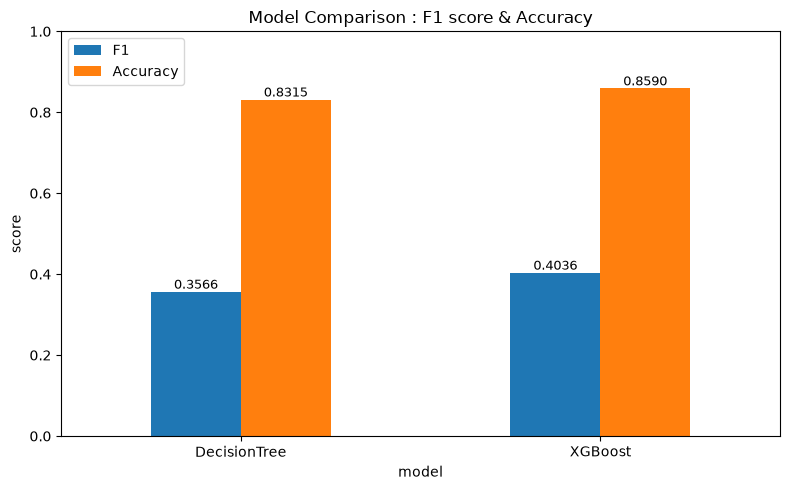

In [2]:
score_df = pd.DataFrame({
    'model': ['DecisionTree', 'XGBoost'],
    'F1': [dt_f1, xgb_f1],
    'Accuracy': [dt_acc, xgb_acc],
}).set_index('model').round(4)
display(score_df)

ax = score_df.plot(kind='bar', figsize=(8, 5), rot=0)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.4f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.title('Model Comparison : F1 score & Accuracy')
plt.ylabel('score')
plt.ylim(0, 1)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 3. 커밋 이력

In [3]:
import subprocess
print(subprocess.run(['git', 'log', '--oneline', '-n', '20'],
                     capture_output=True, text=True, encoding='utf-8').stdout)

a55a29d Merge pull request #2 from skyhyuny/B_branch
6c38758 Merge branch 'main' into B_branch
9b7ad76 [B] XGBoost 모델링 코드 추가, DecisionTree max_depth [3, 7] 실험
9c1005e [Admin] DecisionTree max_depth 후보를 [5, 10, 15] 로 조정
f548ead Merge pull request #1 from skyhyuny/A_branch
08e8a71 [A] DecisionTree 모델링 코드 추가
38d5e61 [Admin] 작업 공간 생성
5d65db6 Initial commit

